# Chapter 19: Web Scraping in Parallel

In [1]:
from multiprocessing import Process
import multiprocessing
import os
import queue
import random
import re
import threading
import time
from urllib.parse import urljoin

from bs4 import BeautifulSoup
from dotenv import load_dotenv
import psycopg
import requests
from tabulate import tabulate

## MultiThreaded Crawling

In [2]:
def print_time(threadName, delay, iterations):
    start = int(time.time())
    for i in range(iterations):
        time.sleep(delay)
        print(f"{int(time.time() - start)} -- {threadName}")

In [3]:
threads = [
    threading.Thread(target=print_time, args=("Fizz", 1, 33)),
    threading.Thread(target=print_time, args=("Buzz", 3, 20)),
    threading.Thread(target=print_time, args=("Counter", 0.5, 55)),
]

print([t.start() for t in threads])
print()
print([t.join() for t in threads])

[None, None, None]

1 -- Counter
1 -- Fizz
1 -- Counter
2 -- Counter
2 -- Fizz
2 -- Counter
3 -- Counter
3 -- Buzz
3 -- Fizz
3 -- Counter
4 -- Counter
4 -- Fizz
4 -- Counter
5 -- Counter
5 -- Fizz
5 -- Counter
6 -- Counter
6 -- Buzz
6 -- Fizz
6 -- Counter
7 -- Counter
7 -- Fizz
7 -- Counter
8 -- Counter
8 -- Fizz
8 -- Counter
9 -- Counter
9 -- Buzz
9 -- Fizz
9 -- Counter
10 -- Counter
10 -- Fizz
10 -- Counter
11 -- Counter
11 -- Fizz
11 -- Counter
12 -- Counter
12 -- Buzz
12 -- Fizz
12 -- Counter
13 -- Counter
13 -- Fizz
13 -- Counter
14 -- Counter
14 -- Fizz
14 -- Counter
15 -- Counter
15 -- Buzz
15 -- Fizz
15 -- Counter
16 -- Counter
16 -- Fizz
16 -- Counter
17 -- Counter
17 -- Fizz
17 -- Counter
18 -- Counter
18 -- Buzz
18 -- Fizz
18 -- Counter
19 -- Counter
19 -- Fizz
19 -- Counter
20 -- Counter
20 -- Fizz
20 -- Counter
21 -- Counter
21 -- Buzz
21 -- Fizz
21 -- Counter
22 -- Counter
22 -- Fizz
22 -- Counter
23 -- Counter
23 -- Fizz
23 -- Counter
24 -- Counter
24 -- Buzz
24 -- Fizz


In [3]:
WIKI_SCRAPED_URLS = 0
WIKI_VISITED = set()

def get_links(thread_name, bs):
    print(f"Gettings links in {thread_name}")
    links = bs.find("div", {"id": "bodyContent"}).find_all(
        "a",
        href = re.compile(r"^(?:https://en\.wikipedia\.org)?/wiki/[^:#]+$"),
    )
    links = [link.get("href") for link in links]
    return [link for link in links if link not in WIKI_VISITED]

def scrape_article(thread_name, path):
    """Recursively find links on Wikipedia page,
    then follow a random link, with artficial 3 sec delay.
    """
    global WIKI_SCRAPED_URLS
    global WIKI_VISITED

    WIKI_VISITED.add(path)
    print(f"{thread_name}: Scraping {path!r} ...")
    # time.sleep(3)
    resp = requests.get(
        urljoin("https://en.wikipedia.org", path),
        headers={"User-Agent": "Mr.Robot-Linux_Machine"}
    )
    bs = BeautifulSoup(resp.text)
    title = bs.find("h1").get_text(strip=True)
    print("\tTitle:", title)
    # links = bs.find("div", {"id": "bodyContent"}).find_all(
    #     "a",
    #     # href=re.compile("^(/wiki/)((?!:).)*$"),
    #     href = re.compile(r"^(?:https://en\.wikipedia\.org)?/wiki/[^:#]+$"),
    # )
    links = get_links(thread_name, bs)

    if WIKI_SCRAPED_URLS >= 100:  # stop if the scraping limit hits
        return
    if len(links) > 0:
        newArticle = links[random.randint(0, len(links) - 1)]
        WIKI_SCRAPED_URLS += 1
        scrape_article(thread_name, newArticle)
    else:
        print("No links found.")

In [5]:
threads = [
    threading.Thread(target=scrape_article, args=("Thread 1", "/wiki/Kevin_Bacon")),
    threading.Thread(target=scrape_article, args=("Thread 2", "/wiki/Monty_Python")),
]

print([t.start() for t in threads])
print([t.join() for t in threads])

Thread 1: Scraping '/wiki/Kevin_Bacon' ...
Thread 2: Scraping '/wiki/Monty_Python' ...
[None, None]
	Title: Kevin Bacon
Gettings links in Thread 1
Thread 1: Scraping 'https://en.wikipedia.org/wiki/Rebel_Without_a_Cause' ...
	Title: Monty Python
Gettings links in Thread 2
Thread 2: Scraping "https://en.wikipedia.org/wiki/Monty_Python's_The_Meaning_of_Life" ...
	Title: Rebel Without a Cause
Gettings links in Thread 1
Thread 1: Scraping 'https://en.wikipedia.org/wiki/List_of_hood_films' ...
	Title: Monty Python's The Meaning of Life
Gettings links in Thread 2
Thread 2: Scraping "https://en.wikipedia.org/wiki/Bert_Fegg's_Nasty_Book_for_Boys_and_Girls" ...
	Title: List of hood films
Gettings links in Thread 1
Thread 1: Scraping 'https://en.wikipedia.org/wiki/Hispanic_Americans' ...
	Title: Bert Fegg's Nasty Book for Boys and Girls
Gettings links in Thread 2
Thread 2: Scraping 'https://en.wikipedia.org/wiki/Fairy_Tales_(Jones_book)' ...
	Title: Fairy Tales(Jones book)
Gettings links in Threa

### Race Conditions and Queues

In [4]:
load_dotenv("./.env")
db_config = {
    "dbname": os.getenv("POSTGRES_DB"),
    "user": os.getenv("POSTGRES_USER"),
    "password": os.getenv("POSTGRES_PASSWORD"),
    "host": os.getenv("POSTGRES_HOST"),
    "port": os.getenv("POSTGRES_PORT"),
}

# with psycopg.connect(**db_config) as conn:
#     conn.execute("""DROP TABLE IF EXISTS wiki_articles;""")
#     conn.commit()

In [5]:
with psycopg.connect(**db_config) as conn:
    conn.execute("""
    CREATE TABLE IF NOT EXISTS wiki_articles (
        id BIGINT GENERATED ALWAYS AS IDENTITY PRIMARY KEY,
        title TEXT,
        url TEXT NOT NULL UNIQUE,
        scraped_at TIMESTAMPTZ NOT NULL DEFAULT now()
    );""")
    conn.commit()

In [6]:
with psycopg.connect(**db_config) as conn:
    conn.execute(
        "INSERT INTO wiki_articles (title, url) VALUES (%s, %s)",
        ("PostgreSQL", "https://en.wikipedia.org/wiki/PostgreSQL")
    )

In [7]:
with psycopg.connect(**db_config) as conn:
  with conn.cursor() as cur:
    cur.execute("SELECT * FROM wiki_articles;")
    # Get column names from cursor description
    column_names = [desc[0] for desc in cur.description]
    rows = cur.fetchall()

print(tabulate(rows, headers=column_names, tablefmt="psql"))

+------+------------+------------------------------------------+----------------------------------+
|   id | title      | url                                      | scraped_at                       |
|------+------------+------------------------------------------+----------------------------------|
|    1 | PostgreSQL | https://en.wikipedia.org/wiki/PostgreSQL | 2026-10-13 07:34:50.778492+00:00 |
+------+------------+------------------------------------------+----------------------------------+


In [8]:
def wiki_storage(wiki_queue: queue.Queue) -> None:
    with psycopg.connect(**db_config) as conn:
        while True:
            if wiki_queue.empty():
                continue
            article_item = wiki_queue.get()
            rows = conn.execute(
                "SELECT * FROM wiki_articles WHERE url = %s;", (article_item["url"],)
            )
            if rows.rowcount == 0:
                print(f"Storing article: {article_item['title']!r}")
                conn.execute(
                    "INSERT INTO wiki_articles (title, url) VALUES (%s, %s)",
                    (article_item["title"], article_item["url"]),
                )
                conn.commit()
            else:
                print(f"Article already exists: {article_item['title']!r}")

In [9]:
WIKI_SCRAPED_URLS = 0
WIKI_VISITED = set()
WIKI_QUEUE = queue.Queue()

def scrape_wiki_article(thread_name, url_path):
    global WIKI_SCRAPED_URLS
    global WIKI_VISITED
    global WIKI_QUEUE

    WIKI_VISITED.add(url_path)
    print(f"{thread_name}: Scraping {url_path!r} ...")
    resp = requests.get(
        urljoin("https://en.wikipedia.org", url_path),
        headers={"User-Agent": "Mr.Robot-Linux_Machine"}
    )
    links = get_links(thread_name, BeautifulSoup(resp.text, "lxml"))

    if WIKI_SCRAPED_URLS >= 1000:  # stop if the scraping limit hits
        return
    if len(links) > 0:
        for url in links:
            resp = requests.get(
                urljoin("https://en.wikipedia.org", url),
                headers={"User-Agent": "Mr.Robot-Linux_Machine"}
            )
            bs = BeautifulSoup(resp.text, "lxml")
            title = bs.find("h1").get_text(strip=True)
            WIKI_QUEUE.put({"title": title, "url": url})
        new_article = links[random.randint(0, len(links) - 1)]
        WIKI_SCRAPED_URLS += 1
        scrape_article(thread_name, new_article)
    else:
        print("No links found.")

In [10]:
threads = [
    threading.Thread(target=scrape_wiki_article, args=("Thread 01", "/wiki/Computer_programming")),
    threading.Thread(target=scrape_wiki_article, args=("Thread 02", "/wiki/Invention")),
    threading.Thread(target=scrape_wiki_article, args=("Thread 03", "/wiki/Engineering & Technology")),
    threading.Thread(target=wiki_storage, args=(WIKI_QUEUE,)),
]

print([t.start() for t in threads])
print([t.join() for t in threads])

Thread 01: Scraping '/wiki/Computer_programming' ...
Thread 02: Scraping '/wiki/Invention' ...
Thread 03: Scraping '/wiki/Engineering & Technology' ...
[None, None, None, None]
Gettings links in Thread 03
Gettings links in Thread 02
Storing article: 'Institution of Engineering and Technology'
Storing article: 'Invention (disambiguation)'
Gettings links in Thread 01
Storing article: 'Inventor (disambiguation)'
Storing article: 'Institution of Electrical Engineers'
Storing article: 'Institution of Incorporated Engineers'
Storing article: 'The Electrical Experimenter'
Storing article: 'Software development'
Thread 03: Scraping 'https://en.wikipedia.org/wiki/Institution_of_Engineering_and_Technology' ...
Storing article: 'Professional Publishers Association'
Storing article: 'Novelty (patent)'
Storing article: 'Data modeling'
	Title: Institution of Engineering and Technology
Gettings links in Thread 03
Thread 03: Scraping 'https://en.wikipedia.org/wiki/Manufacturing_engineering' ...
Storin


KeyboardInterrupt


KeyboardInterrupt



In [15]:
with psycopg.connect(**db_config) as conn:
  with conn.cursor() as cur:
    cur.execute("SELECT * FROM wiki_articles LIMIT 25;")
    # Get column names from cursor description
    column_names = [desc[0] for desc in cur.description]
    rows = cur.fetchall()

print(tabulate(rows, headers=column_names, tablefmt="psql"))

+------+-------------------------------------------+-------------------------------------------------------------------------+----------------------------------+
|   id | title                                     | url                                                                     | scraped_at                       |
|------+-------------------------------------------+-------------------------------------------------------------------------+----------------------------------|
|    1 | PostgreSQL                                | https://en.wikipedia.org/wiki/PostgreSQL                                | 2026-10-13 07:34:50.778492+00:00 |
|    2 | Institution of Engineering and Technology | https://en.wikipedia.org/wiki/Institution_of_Engineering_and_Technology | 2026-10-13 07:35:08.987871+00:00 |
|    3 | Invention (disambiguation)                | https://en.wikipedia.org/wiki/Invention_(disambiguation)                | 2026-10-13 07:35:08.994710+00:00 |
|    4 | Inventor (disambigu

### More Features of the Threading Module

In [3]:
class Crawler(threading.Thread):
    def __init__(self):
        threading.Thread.__init__(self)
        self.done = False

    def isDone(self):
        return self.done

    def run(self):
        time.sleep(5)
        self.done = True
        raise Exception("Something bad happened!")

In [4]:
t = Crawler()
t.start()

while True:
    if t.isDone():
        print("Done.")
    if not t.is_alive():
        t = Crawler()
        t.start()
    time.sleep(0.5)

Exception in thread Thread-5:
Traceback (most recent call last):
  File "/usr/lib/python3.14/threading.py", line 1082, in _bootstrap_inner
    self._context.run(self.run)
    ~~~~~~~~~~~~~~~~~^^^^^^^^^^
  File "/tmp/ipykernel_41918/3628720695.py", line 12, in run
    raise Exception("Something bad happened!")
Exception: Something bad happened!


Done.
Done.


Exception in thread Thread-6:
Traceback (most recent call last):
  File "/usr/lib/python3.14/threading.py", line 1082, in _bootstrap_inner
    self._context.run(self.run)
    ~~~~~~~~~~~~~~~~~^^^^^^^^^^
  File "/tmp/ipykernel_41918/3628720695.py", line 12, in run
    raise Exception("Something bad happened!")
Exception: Something bad happened!


Done.


KeyboardInterrupt: 

Exception in thread Thread-7:
Traceback (most recent call last):
  File "/usr/lib/python3.14/threading.py", line 1082, in _bootstrap_inner
    self._context.run(self.run)
    ~~~~~~~~~~~~~~~~~^^^^^^^^^^
  File "/tmp/ipykernel_41918/3628720695.py", line 12, in run
    raise Exception("Something bad happened!")
Exception: Something bad happened!


## Multiple Processes

In [30]:
%%writefile worker.py

from multiprocessing import Process
import time

def print_time(thread_name, delay, iterations):
    start = int(time.time())
    for i in range(iterations):
        time.sleep(delay)
        seconds_elapsed = str(int(time.time()) - start)
        print(thread_name if thread_name else seconds_elapsed)

Overwriting worker.py


In [32]:
from worker import print_time

processes = [
    Process(target=print_time, args=("Counter", 1, 100)),
    Process(target=print_time, args=("Fizz", 3, 33)),
    Process(target=print_time, args=("Buzz", 5, 20)),
    Process(target=print_time, args=("FizzBuzz", 7, 10)),
]

[p.start() for p in processes]
[p.join() for p in processes]

FizzBuzz
FizzBuzz
FizzBuzz
FizzBuzz
FizzBuzz
FizzBuzz
FizzBuzz
FizzBuzz
Counter
Counter
Counter
Counter
Counter
Counter
Counter
Counter
Counter
Counter
Counter
Counter
Counter
Counter
Counter
Counter
Counter
Counter
Counter
Counter
Counter
Counter
Counter
Counter
Counter
Counter
Counter
Counter
Counter
Counter
Counter
Counter
Counter
Counter
Counter
Counter
Counter
Counter
Counter
Counter
Counter
Counter
Counter
Counter
Counter
Counter
Counter
Counter
Counter
Counter
Counter
Counter
Counter
Counter
Counter
Counter
Fizz
Fizz
Fizz
Fizz
Fizz
Fizz
Fizz
Fizz
Fizz
Fizz
Fizz
Fizz
Fizz
Fizz
Fizz
Fizz
Fizz
Fizz
Buzz
Buzz
Buzz
Buzz
Buzz
Buzz
Buzz
Buzz
Buzz
Buzz
Buzz


Process Process-40:
Process Process-37:
Traceback (most recent call last):
Traceback (most recent call last):
  File "/usr/lib/python3.14/multiprocessing/process.py", line 320, in _bootstrap
    self.run()
    ~~~~~~~~^^
  File "/usr/lib/python3.14/multiprocessing/process.py", line 108, in run
    self._target(*self._args, **self._kwargs)
    ~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/javohir/Engineering/Web-Scraping-with-Python/worker.py", line 8, in print_time
    time.sleep(delay)
    ~~~~~~~~~~^^^^^^^
  File "/usr/lib/python3.14/multiprocessing/process.py", line 320, in _bootstrap
    self.run()
    ~~~~~~~~^^
  File "/usr/lib/python3.14/multiprocessing/process.py", line 108, in run
    self._target(*self._args, **self._kwargs)
    ~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
KeyboardInterrupt
  File "/home/javohir/Engineering/Web-Scraping-with-Python/worker.py", line 8, in print_time
    time.sleep(delay)
    ~~~~~~~~~~^^^^^^^
KeyboardInterrupt
Process Process-38:
Traceb

KeyboardInterrupt: 

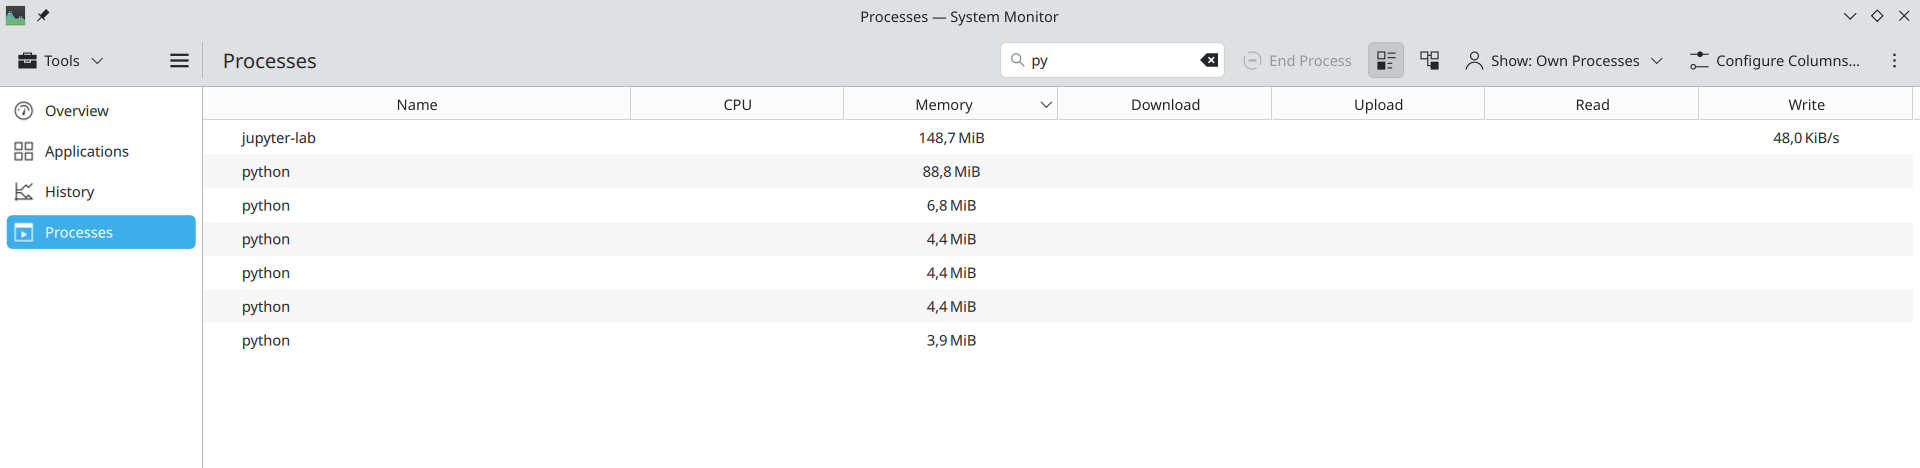

---

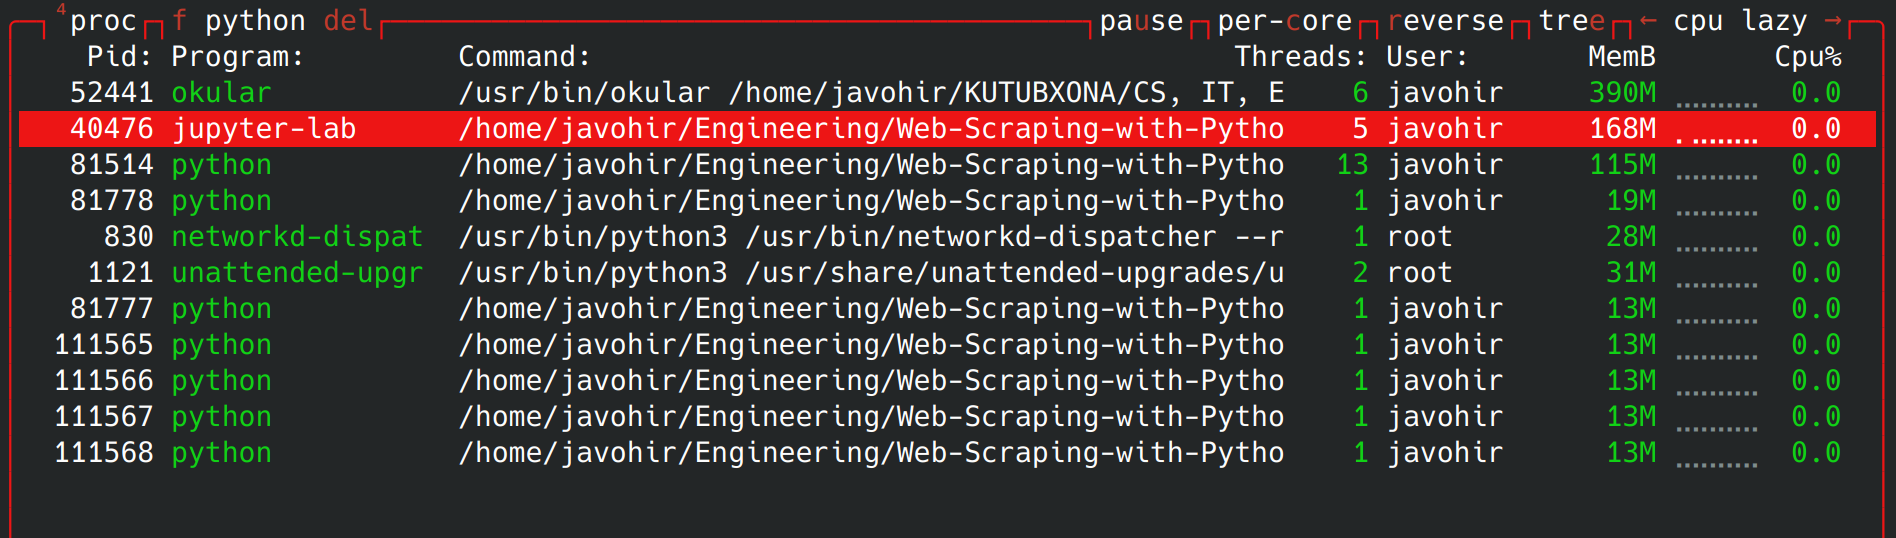

In [35]:
print("Child PID:", os.getpid())
print("Parent PID:", os.getppid())

Child PID: 81514
Parent PID: 40476


### Multiprocess Crawling

In [4]:
%%writefile wiki_scraper.py

import os
import random
import re
from urllib.parse import urljoin

from bs4 import BeautifulSoup
import requests

WIKI_SCRAPED_URLS = 0
WIKI_VISITED = set()

def get_links(bs):
    links = bs.find("div", {"id": "bodyContent"}).find_all(
        "a",
        href=re.compile(r"^(?:https://en\.wikipedia\.org)?/wiki/[^:#]+$"),
    )
    links = [link.get("href") for link in links]
    return [link for link in links if link not in WIKI_VISITED]

def scrape_article(path):
    """Recursively find links on Wikipedia page,
    then follow a random link, with artficial 3 sec delay.
    """
    global WIKI_SCRAPED_URLS
    global WIKI_VISITED

    WIKI_VISITED.add(path)
    # print(f"> Scraping {path!r} ...")
    # time.sleep(3)
    resp = requests.get(
        urljoin("https://en.wikipedia.org", path),
        headers={"User-Agent": "Mr.Robot-Linux_Machine"}
    )
    bs = BeautifulSoup(resp.text, "lxml")
    title = bs.find("h1").get_text(strip=True)
    print(f"Scraping {bs.find('h1').get_text(strip=True)} -> PID: {os.getpid()}")
    # links = bs.find("div", {"id": "bodyContent"}).find_all(
    #     "a",
    #     # href=re.compile("^(/wiki/)((?!:).)*$"),
    #     href = re.compile(r"^(?:https://en\.wikipedia\.org)?/wiki/[^:#]+$"),
    # )
    links = get_links(bs)

    if WIKI_SCRAPED_URLS >= 100:  # stop if the scraping limit hits
        return
    if len(links) > 0:
        new_article = links[random.randint(0, len(links) - 1)]
        WIKI_SCRAPED_URLS += 1
        scrape_article(new_article)
    else:
        print("No links found.")

Overwriting wiki_scraper.py


In [5]:
from wiki_scraper import scrape_article

processes = [
    Process(target=scrape_article, args=("/wiki/Uzbekistan",)),
    Process(target=scrape_article, args=("/wiki/Central_Asia",)),
]
[p.start() for p in processes]
[p.join() for p in processes]

Process Process-3:
Process Process-4:
Traceback (most recent call last):
Traceback (most recent call last):
  File "/usr/lib/python3.14/multiprocessing/process.py", line 320, in _bootstrap
    self.run()
    ~~~~~~~~^^
  File "/usr/lib/python3.14/multiprocessing/process.py", line 108, in run
    self._target(*self._args, **self._kwargs)
    ~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/javohir/Engineering/Web-Scraping-with-Python/wiki_scraper.py", line 50, in scrape_article
    scrape_article(new_article)
    ~~~~~~~~~~~~~~^^^^^^^^^^^^^
  File "/home/javohir/Engineering/Web-Scraping-with-Python/wiki_scraper.py", line 50, in scrape_article
    scrape_article(new_article)
    ~~~~~~~~~~~~~~^^^^^^^^^^^^^
  File "/home/javohir/Engineering/Web-Scraping-with-Python/wiki_scraper.py", line 50, in scrape_article
    scrape_article(new_article)
    ~~~~~~~~~~~~~~^^^^^^^^^^^^^
  [Previous line repeated 41 more times]
  File "/home/javohir/Engineering/Web-Scraping-with-Python/wiki_scrape

KeyboardInterrupt: 

Scraping Central Asia -> PID: 143489
Scraping Oghuz Yabgu State -> PID: 143489
Scraping Turks in Romania -> PID: 143489
Scraping Barsils -> PID: 143489
Scraping Iran -> PID: 143489
Scraping Barbat(lute) -> PID: 143489
Scraping Hadda, Afghanistan -> PID: 143489
Scraping JSTOR -> PID: 143489
Scraping ProPublica -> PID: 143489
Scraping Ledger-Enquirer -> PID: 143489
Scraping The Boston Globe -> PID: 143489
Scraping Haverhill Gazette -> PID: 143489
Scraping Sampan(newspaper) -> PID: 143489
Scraping Boston Gazette -> PID: 143489
Scraping Jerome V. C. Smith -> PID: 143489
Scraping Josiah Quincy Jr. -> PID: 143489
Scraping Henry Van Brunt -> PID: 143489
Scraping The New York Times -> PID: 143489
Scraping Gareth Cook -> PID: 143489
Scraping Nuclear weapon -> PID: 143489
Scraping Nuclear holocaust -> PID: 143489
Scraping Overhead power line -> PID: 143489
Scraping Helicopter -> PID: 143489
Scraping Vietnam War -> PID: 143489
Scraping Dow Chemical Company -> PID: 143489
Scraping Stryker Corporat

### Communicating Between Processes

In [2]:
%%writefile wiki_scraper_parallel.py

import os
import random
import re
import time
from urllib.parse import urljoin

from bs4 import BeautifulSoup
import requests

def task_delegator(task_queue, urls_queue):
    # Initialize with a task for each process
    visited = ["/wiki/Kevin_Bacon", "/wiki/"]
    task_queue.put("/wiki/Kevin_Bacon")
    task_queue.put("/wiki/Monty_Python")

    while True:
        # Check to see if there are new links in the
        #  urls_queue for processing
        if not urls_queue.empty():
            links = [link for link in urls_queue.get() if link not in visited]
            for link in links:
                # Add new link to the task_queue
                task_queue.put(link)


def get_links(bs):
    links = bs.find("div", {"id": "bodyContent"}).find_all(
        "a",
        href=re.compile(r"^(?:https://en\.wikipedia\.org)?/wiki/[^:#]+$"),
    )
    return [link.get("href") for link in links]


def scrape_article(task_queue, urls_queue):
    while True:
        while task_queue.empty():
            time.sleep(0.1)
        path = task_queue.get()
        resp = requests.get(
            urljoin("https://en.wikipedia.org", path),
            headers={"User-Agent": "Mr.Robot-Linux_Machine"}
        )
        bs = BeautifulSoup(resp.text, "lxml")
        print(f"Scraping {bs.find('h1').get_text(strip=True)} -> PID: {os.getpid()}")
        links = get_links(bs)
        # Send these to the delegator for processing
        urls_queue.put(links)

Overwriting wiki_scraper_parallel.py


In [3]:
from wiki_scraper_parallel import task_delegator, scrape_article

processes = []
task_queue = multiprocessing.Queue()
urls_queue = multiprocessing.Queue()
processes = [
    multiprocessing.Process(
        target=task_delegator, args=(task_queue, urls_queue)
    ),
    multiprocessing.Process(
        target=scrape_article, args=(task_queue, urls_queue)
    ),
    multiprocessing.Process(
        target=scrape_article, args=(task_queue, urls_queue)
    ),
]

for p in processes:
    p.start()

In [4]:
for p in processes:
    p.join()

Scraping Kevin Bacon -> PID: 183000
Scraping Kevin Bacon (disambiguation) -> PID: 183000
Scraping Kevin Bacon filmography -> PID: 183000
Scraping Kyra Sedgwick -> PID: 183000
Scraping Edmund Bacon (architect) -> PID: 183000
Scraping Leading actor -> PID: 183000
Scraping Actor Awards -> PID: 183000
Scraping Diner(1982 film) -> PID: 183000
Scraping Footloose -> PID: 183000
Scraping A Few Good Men -> PID: 183000
Scraping Mystic River(film) -> PID: 183000
Scraping Friday the 13th(1980 film) -> PID: 183000
Scraping The River Wild -> PID: 183000
Scraping The Woodsman(film) -> PID: 183000
Scraping Crazy, Stupid, Love -> PID: 183000
Scraping Patriots Day(film) -> PID: 183000
Scraping Loverboy(2005 film) -> PID: 183000
Scraping Actor Award for Outstanding Performance by a Male Actor in a Television Movie or Limited Series -> PID: 183000
Scraping HBO -> PID: 183000
Scraping The Following -> PID: 183000
Scraping Amazon Prime Video -> PID: 183000
Scraping City on a Hill(TV series) -> PID: 183000
S

Process Process-1:
Process Process-3:
Process Process-2:
Traceback (most recent call last):
  File "/usr/lib/python3.14/multiprocessing/process.py", line 320, in _bootstrap
    self.run()
    ~~~~~~~~^^
  File "/usr/lib/python3.14/multiprocessing/process.py", line 108, in run
    self._target(*self._args, **self._kwargs)
    ~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/javohir/Engineering/Web-Scraping-with-Python/wiki_scraper_parallel.py", line 20, in task_delegator
    if not urls_queue.empty():
           ~~~~~~~~~~~~~~~~^^
  File "/usr/lib/python3.14/multiprocessing/queues.py", line 127, in empty
    return not self._poll()
               ~~~~~~~~~~^^
  File "/usr/lib/python3.14/multiprocessing/connection.py", line 264, in poll
    return self._poll(timeout)
           ~~~~~~~~~~^^^^^^^^^
  File "/usr/lib/python3.14/multiprocessing/connection.py", line 458, in _poll
    r = wait([self], timeout)
  File "/usr/lib/python3.14/multiprocessing/connection.py", line 1184, in wai

KeyboardInterrupt: 

### Multiprocess Crawling—Another Approach

`$ python my_crawler.py website1`

`$ python my_crawler.py website2`